# Notebook 3: Pengiriman Gambar Manual ke Hardware Seeed Grove Vision AI V2 (`tflm_pp2_full_v1`)

Notebook ini berfungsi sebagai **pengirim gambar interaktif dari Laptop ke Seeed Grove Vision AI Module V2 (Cortex-M55 + Ethos-U55 NPU)** melalui kabel USB-C (`/dev/ttyACM0` atau `/dev/ttyACM1` @ `921600` baud).

### Alur Kerja End-to-End:
1. **Laptop (Notebook 3)**: Membaca file gambar (`test/hen`, `test/cock`, `valid/`, atau citra kosong), mengubah ukurannya menjadi `160×160 RGB uint8` (`76.800 byte`), lalu mengirimkannya ke **Grove Vision AI V2** dengan protokol `"PP2IR"`.
2. **Grove Vision AI V2 (`tflm_pp2_full_v1`)**: Menerima gambar menggunakan polling register hardware `DW_APB_UART0` berkecepatan tinggi (`~15 ns/byte`), menghitung standar deviasi piksel (`pixel_std`), melakukan kuantisasi `uint8 -> int8` secara *on-device*, dan menjalankan inferensi pada akselerator **Arm Ethos-U55 NPU**.
3. **Transmisi I2C 5-Byte ke ESP32 (`0x55`)**: Grove **hanya mengirimkan hasil klasifikasi dan konfidensinya** dalam paket **5 Byte** `[0xAA, class_id, conf_int, conf_dec, checksum]` ke ESP32.
4. **ESP32 (`PP2/firmware/main.ino`)**: Memegang kendali penuh atas **State Machine Layar OLED SSD1306 (`0x3C`)** dan **Keputusan Sudut Motor Servo (`GPIO 18`)**:
   - `class_id == 0` (**Betina**) $\rightarrow$ OLED: `STATE_SORT_BETINA`, Servo: **`0°` (Kiri)**
   - `class_id == 1` (**Jantan**) $\rightarrow$ OLED: `STATE_SORT_JANTAN`, Servo: **`180°` (Kanan)**
   - `class_id == 2` (**Undefined**) $\rightarrow$ OLED: `STATE_UNDEFINED_NO_EGG` / `STATE_UNDEFINED_LOW_CONF`, Servo: **`90°` (Standby)**

> **Catatan Penting**: Jika Anda ingin melihat grafik hasil (`PP2_JSON`) langsung di dalam Notebook ini, pastikan **`picocom` sudah ditutup** (`Ctrl+A` lalu `Ctrl+X`). Jika `picocom` dibiarkan terbuka di terminal, gambar tetap terkirim secara *write-only* dan hasilnya akan langsung tercetak di layar `picocom` Anda.

In [1]:
import os
import glob
import time
import json
import struct
import subprocess
import serial
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

def detect_grove_port(default_port="/dev/ttyACM0"):
    """Otomatis mendeteksi port /dev/ttyACM* yang aktif (misal /dev/ttyACM0 atau /dev/ttyACM1)."""
    if default_port and os.path.exists(default_port):
        return default_port
    acm_ports = sorted(glob.glob("/dev/ttyACM*"))
    if acm_ports:
        return acm_ports[0]
    return default_port or "/dev/ttyACM0"

def is_picocom_active():
    """
    Mendeteksi apakah picocom/minicom sedang benar-benar aktif berjalan (state R/S).
    Jika ada proses picocom yang berstatus Stopped ('T' akibat Ctrl+Z), otomatis dibersihkan.
    """
    try:
        pids = subprocess.check_output(["pgrep", "-f", "picocom|minicom"], text=True).strip().splitlines()
        active_found = False
        for pid in pids:
            pid = pid.strip()
            if not pid:
                continue
            state = subprocess.check_output(["ps", "-o", "state=", "-p", pid], text=True).strip()
            if state.startswith("T"):
                subprocess.run(["kill", "-9", pid], check=False)
            else:
                active_found = True
        return active_found
    except subprocess.CalledProcessError:
        return False

SERIAL_PORT = detect_grove_port()
BAUD_RATE   = 921600
IMG_SIZE    = (160, 160)

BASE_DIR = os.path.abspath(os.path.join(os.getcwd(), ".."))
DATA_DIR = os.path.join(BASE_DIR, "data", "Sexing-Chicken-2")

def ping_grove_board(port=None, baud=BAUD_RATE, timeout=0.5):
    """Memeriksa apakah firmware tflm_pp2_full_v1 di Grove Vision AI V2 siap menerima gambar."""
    global SERIAL_PORT
    SERIAL_PORT = detect_grove_port(port or SERIAL_PORT)
    picocom_open = is_picocom_active()
    if picocom_open:
        print(f"[INFO] Port aktif: {SERIAL_PORT}. Terdeteksi 'picocom' sedang berjalan di terminal.")
        print("       -> Jika ingin melihat grafik PP2_JSON di Notebook ini, tutup picocom (Ctrl+A Ctrl+X).")
        print("       -> Jika picocom tetap dibuka, pengiriman gambar tetap jalan dan hasilnya tampil di picocom!")
    try:
        with serial.Serial(SERIAL_PORT, baud, timeout=timeout) as ser:
            ser.write(b"PP2IP")
            ser.flush()
            if picocom_open:
                print(f"[OK] Perintah PING ('PP2IP') dikirim ke {SERIAL_PORT} (cek balasan PP2_PONG:READY di picocom).")
                return True
            t0 = time.time()
            while time.time() - t0 < timeout:
                line = ser.readline().decode("utf-8", errors="ignore").strip()
                if "PP2_PONG:READY" in line:
                    print(f"[OK] Grove Vision AI V2 terhubung di {SERIAL_PORT} @ {baud} bps -> Status: {line}")
                    return True
        print(f"[WARN] Tidak ada respons PP2_PONG dari {SERIAL_PORT}. Tekan tombol RESET di board Grove lalu coba lagi.")
        return False
    except Exception as e:
        print(f"[ERROR] Gagal membuka port {SERIAL_PORT}: {e}")
        return False

ping_grove_board()

[INFO] Port aktif: /dev/ttyACM0. Terdeteksi 'picocom' sedang berjalan di terminal.
       -> Jika ingin melihat grafik PP2_JSON di Notebook ini, tutup picocom (Ctrl+A Ctrl+X).
       -> Jika picocom tetap dibuka, pengiriman gambar tetap jalan dan hasilnya tampil di picocom!
[OK] Perintah PING ('PP2IP') dikirim ke /dev/ttyACM0 (cek balasan PP2_PONG:READY di picocom).


True

## 1. Fungsi Pengiriman Gambar ke Hardware NPU & Visualisasi Hasil

In [2]:
ESP32_STATE_MAP = {
    (0, "OK"):          ("STATE_SORT_BETINA",        "0° (Sortir Kiri)",    "#2ecc71"),
    (1, "OK"):          ("STATE_SORT_JANTAN",        "180° (Sortir Kanan)", "#3498db"),
    (2, "BLANK_FRAME"): ("STATE_UNDEFINED_NO_EGG",   "90° (Standby / Hold)","#95a5a6"),
    (2, "LOW_CONF"):    ("STATE_UNDEFINED_LOW_CONF", "90° (Standby / Hold)","#f39c12"),
}

def send_image_to_grove_npu(image_input, title_label=None, port=None, baud=BAUD_RATE, show_plot=True):
    """
    Mengirim gambar 160x160 RGB (dari path file atau array numpy uint8) ke Grove Vision AI V2,
    menerima hasil inferensi Ethos-U55 NPU, dan menampilkan rincian paket I2C 5-Byte ke ESP32.
    """
    active_port = detect_grove_port(port or SERIAL_PORT)
    if isinstance(image_input, str):
        if not os.path.isfile(image_input):
            raise FileNotFoundError(f"File gambar tidak ditemukan: {image_input}")
        pil_img = Image.open(image_input).convert("RGB").resize(IMG_SIZE, Image.Resampling.BILINEAR)
        rgb_arr = np.asarray(pil_img, dtype=np.uint8)
        disp_name = title_label if title_label else os.path.basename(image_input)
    elif isinstance(image_input, np.ndarray):
        rgb_arr = image_input.astype(np.uint8)
        assert rgb_arr.shape == (160, 160, 3), "Array harus berukuran (160, 160, 3) uint8"
        disp_name = title_label if title_label else "Synthetic_RGB_160x160"
    else:
        raise ValueError("image_input harus berupa path file (str) atau numpy.ndarray (160,160,3)")

    # --- TAMPILKAN PREVIEW GAMBAR SEBELUM DIKIRIM KE HARDWARE ---
    plt.figure(figsize=(3.2, 3.2))
    plt.imshow(rgb_arr)
    plt.title(f"Akan Dikirim: {disp_name}\n(160x160 RGB)", fontsize=9, fontweight="bold")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

    raw_bytes = rgb_arr.tobytes()
    checksum  = sum(raw_bytes) & 0xFFFF
    crc_bytes = struct.pack("<H", checksum)
    payload   = raw_bytes + crc_bytes

    picocom_open = is_picocom_active()
    serial_logs = []
    result_json = None

    with serial.Serial(active_port, baud, timeout=0.15) as ser:
        if not picocom_open:
            ser.reset_input_buffer()

        # 1. Kirim Command Header "PP2IR"
        ser.write(b"PP2IR")
        ser.flush()
        if picocom_open:
            time.sleep(0.005)
        else:
            t_rdy = time.time()
            while time.time() - t_rdy < 0.25:
                rdy_line = ser.readline().decode("utf-8", errors="ignore").strip()
                if "RDY" in rdy_line:
                    break

        # 2. Alirkan 76.800 byte piksel RGB + 2 byte Checksum (Chunk 256 B + jeda 3 ms)
        chunk_size = 256
        for idx in range(0, len(payload), chunk_size):
            ser.write(payload[idx:idx + chunk_size])
            ser.flush()
            time.sleep(0.003)

        if picocom_open:
            print(f"[SENT] {disp_name} (76.800 B | Checksum: 0x{checksum:04X}) terkirim ke {active_port}! Lihat hasil inferensi di layar picocom.")
            return None

        # 3. Baca laporan Serial & baris PP2_JSON dari Grove Vision AI V2
        t0 = time.time()
        while time.time() - t0 < 3.5:
            line = ser.readline().decode("utf-8", errors="ignore").strip()
            if not line:
                continue
            serial_logs.append(line)
            if line.startswith("PP2_JSON:"):
                json_str = line[len("PP2_JSON:"):].strip()
                result_json = json.loads(json_str)
            elif "[READY] Menunggu upload gambar berikutnya" in line and result_json is not None:
                break

    if result_json is None:
        print("\n".join(serial_logs))
        raise RuntimeError("Gagal menerima PP2_JSON dari Grove Vision AI V2! (Pastikan picocom ditutup jika ingin membaca hasil di Notebook)")

    cls_id = result_json["class_id"]
    reason = result_json["reason"]
    esp_state, esp_servo, bar_color = ESP32_STATE_MAP.get(
        (cls_id, reason), ("STATE_UNDEFINED", "90° (Standby)", "#95a5a6")
    )
    pkt = result_json["i2c_pkt"]
    pkt_hex = f"[0x{pkt[0]:02X}, {pkt[1]}, {pkt[2]}, {pkt[3]}, 0x{pkt[4]:02X}]"

    print("=" * 92)
    print(f"  HASIL INFERENSI HARDWARE GROVE VISION AI V2 (FRAME #{result_json['frame']:03d}) — {disp_name}")
    print("=" * 92)
    print(f"  * Port Aktif               : {active_port} @ {baud} bps")
    print(f"  * Output Mentah NPU (INT8) : Class 0 (Betina) = {result_json['raw_c0']:4d} | Class 1 (Jantan) = {result_json['raw_c1']:4d}")
    print(f"  * Probabilitas Terukur     : P(Betina) = {result_json['p_betina']:6.2f}%   | P(Jantan) = {result_json['p_jantan']:6.2f}%  | Pixel Std = {result_json['pixel_std']:.2f}")
    print(f"  * Keputusan AI (Grove)     : Class {cls_id} -> {result_json['label']} (Confidence: {result_json['conf']:.2f}% | Reason: {reason})")
    print(f"  * Paket I2C 5-B ke ESP32   : {pkt_hex} -> Slave 0x55 ({result_json['i2c_status']})")
    print(f"  * Instruksi ESP32 (main.ino): OLED = {esp_state} | Servo GPIO 18 = {esp_servo}")
    print(f"  * Kecepatan Ethos-U55 NPU  : {result_json['npu_ms']:.2f} ms ({result_json['npu_fps']:.1f} FPS) | Total Cycles: {result_json['npu_total_cyc']:,}")
    print("=" * 92)

    if show_plot:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.35]})
        axes[0].imshow(rgb_arr)
        axes[0].set_title(f"Input: {disp_name}\n(160x160 RGB | Pixel Std: {result_json['pixel_std']:.2f})", fontsize=10, fontweight="bold")
        axes[0].axis("off")

        classes = ["Class 0:\nBetina (hen)", "Class 1:\nJantan (cock)"]
        probs = [result_json["p_betina"], result_json["p_jantan"]]
        colors = ["#2ecc71" if cls_id == 0 else "#bdc3c7", "#3498db" if cls_id == 1 else "#bdc3c7"]
        bars = axes[1].barh(classes, probs, color=colors, height=0.45, edgecolor="black")
        axes[1].axvline(80.0, color="#e74c3c", linestyle="--", linewidth=1.5, label="Ambang Confidence (80%)")
        axes[1].set_xlim(0, 112)
        axes[1].set_xlabel("Confidence (%)", fontweight="bold")
        axes[1].set_title(
            f"Keputusan NPU: {result_json['label'].upper()} ({result_json['conf']:.2f}%)\n"
            f"I2C 5-Byte -> ESP32: {pkt_hex}\n"
            f"ESP32 OLED: {esp_state} | Servo: {esp_servo}",
            fontsize=9.5, fontweight="bold"
        )
        for bar, p in zip(bars, probs):
            axes[1].text(min(p + 2.0, 102.0), bar.get_y() + bar.get_height() / 2, f"{p:.2f}%", va="center", fontweight="bold")
        axes[1].legend(loc="lower right", fontsize=8.5)
        axes[1].grid(axis="x", linestyle=":", alpha=0.6)
        plt.tight_layout()
        plt.show()

    return result_json


## 2. Uji Kirim Gambar Tunggal (`Betina` & `Jantan`) ke Grove Vision AI V2

In [3]:
hen_files  = sorted(glob.glob(os.path.join(DATA_DIR, "test", "hen", "*.jpg")))
cock_files = sorted(glob.glob(os.path.join(DATA_DIR, "test", "cock", "*.jpg")))

print(f"Jumlah sampel uji Betina (hen): {len(hen_files)} | Jantan (cock): {len(cock_files)}")

Jumlah sampel uji Betina (hen): 89 | Jantan (cock): 102


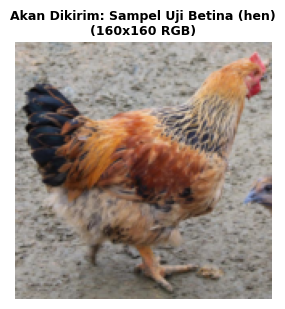

[SENT] Sampel Uji Betina (hen) (76.800 B | Checksum: 0xD7B8) terkirim ke /dev/ttyACM0! Lihat hasil inferensi di layar picocom.


In [5]:
# # 1. Uji Kirim Sampel Betina (Class 0)
res_hen = send_image_to_grove_npu(hen_files[15], title_label="Sampel Uji Betina (hen)")
# time.sleep(0.5)

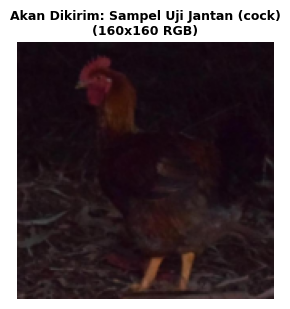

In [ ]:
# 2. Uji Kirim Sampel Jantan (Class 1)
res_cock = send_image_to_grove_npu(cock_files[3], title_label="Sampel Uji Jantan (cock)")

## 3. Uji Kirim Kondisi `Undefined` (Frame Kosong `NO EGG` & Confidence Rendah `< 80%`)

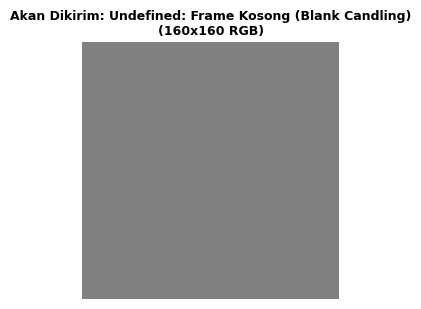

[SENT] Undefined: Frame Kosong (Blank Candling) (76.800 B | Checksum: 0x0000) terkirim ke /dev/ttyACM0! Lihat hasil inferensi di layar picocom.


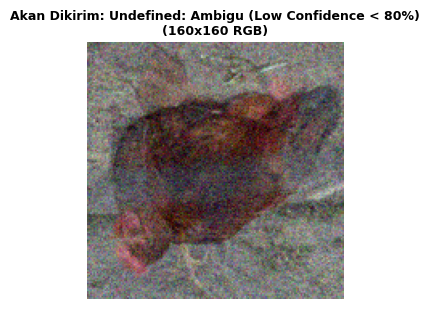

[SENT] Undefined: Ambigu (Low Confidence < 80%) (76.800 B | Checksum: 0x37B0) terkirim ke /dev/ttyACM0! Lihat hasil inferensi di layar picocom.


In [6]:
# Siapkan citra sintetis Blank Frame (No Egg) & Ambigu (Low Confidence < 80%)
blank_rgb = np.full((160, 160, 3), 128, dtype=np.uint8)

img_h = np.asarray(Image.open(hen_files[0]).convert("RGB").resize(IMG_SIZE), dtype=np.float32)
img_c = np.asarray(Image.open(cock_files[1]).convert("RGB").resize(IMG_SIZE), dtype=np.float32)
rng = np.random.default_rng(7)
ambig_rgb = np.clip(0.32 * img_h + 0.68 * np.flipud(img_c) + rng.normal(0, 18, (160, 160, 3)), 0, 255).astype(np.uint8)

# 3A. Uji Gambar Kosong / Tidak Ada Telur (Pixel Std < 12.0 -> STATE_UNDEFINED_NO_EGG)
res_blank = send_image_to_grove_npu(blank_rgb, title_label="Undefined: Frame Kosong (Blank Candling)")

time.sleep(0.5)

# 3B. Uji Gambar Ambigu / Ragu-ragu (Confidence < 80% -> STATE_UNDEFINED_LOW_CONF)
res_ambig = send_image_to_grove_npu(ambig_rgb, title_label="Undefined: Ambigu (Low Confidence < 80%)")

## 4. Simulasi Batch Otomatis Semua State (Demo Live OLED & Servo ESP32)

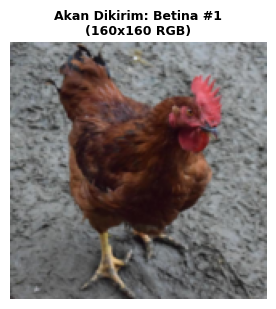

[SENT] Betina #1 (76.800 B | Checksum: 0x56B4) terkirim ke /dev/ttyACM0! Lihat hasil inferensi di layar picocom.


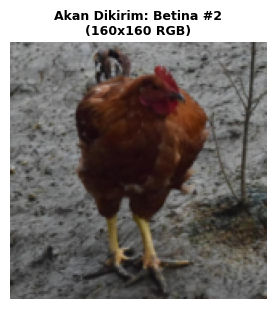

[SENT] Betina #2 (76.800 B | Checksum: 0x0148) terkirim ke /dev/ttyACM0! Lihat hasil inferensi di layar picocom.


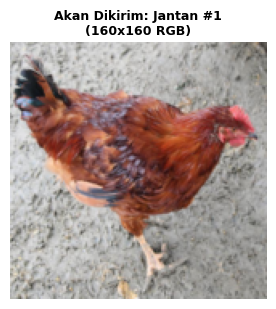

[SENT] Jantan #1 (76.800 B | Checksum: 0x4675) terkirim ke /dev/ttyACM0! Lihat hasil inferensi di layar picocom.


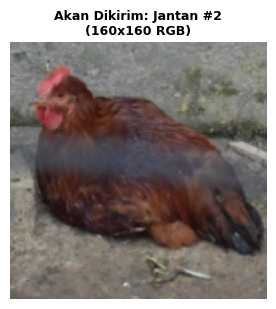

[SENT] Jantan #2 (76.800 B | Checksum: 0x2C62) terkirim ke /dev/ttyACM0! Lihat hasil inferensi di layar picocom.


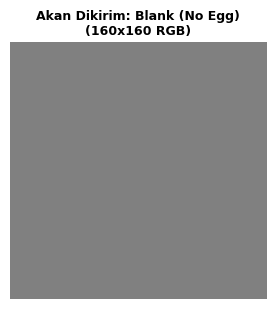

[SENT] Blank (No Egg) (76.800 B | Checksum: 0x0000) terkirim ke /dev/ttyACM0! Lihat hasil inferensi di layar picocom.


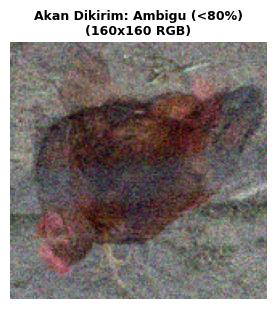

[SENT] Ambigu (<80%) (76.800 B | Checksum: 0x37B0) terkirim ke /dev/ttyACM0! Lihat hasil inferensi di layar picocom.


In [7]:
batch_samples = [
    (hen_files[0],  "Betina #1", 0),
    (hen_files[1],  "Betina #2", 0),
    (cock_files[0], "Jantan #1", 1),
    (cock_files[1], "Jantan #2", 1),
    (blank_rgb,     "Blank (No Egg)", 2),
    (ambig_rgb,     "Ambigu (<80%)", 2),
]

records = []
for idx, (inp, name, target_cls) in enumerate(batch_samples, 1):
    res = send_image_to_grove_npu(inp, title_label=name, show_plot=False)
    if res is not None:
        records.append((idx, name, target_cls, res))
    time.sleep(2.0)  # Jeda 2 detik agar perubahan OLED & gerakan Servo di ESP32 terlihat jelas

if records:
    print("\n" + "=" * 105)
    print("  REKAPITULASI PENGUJIAN BATCH HARDWARE GROVE VISION AI V2 -> ESP32 (OLED & SERVO)")
    print("=" * 105)
    print(f"  {'No':<3} {'Sampel Uji':<18} {'Target':<8} {'Prediksi NPU':<16} {'Conf (%)':<10} {'Paket I2C 5-B ke ESP32':<26} {'Status'}")
    print("-" * 105)
    correct = 0
    for idx, name, target_cls, r in records:
        is_ok = (r['class_id'] == target_cls)
        if is_ok:
            correct += 1
        pkt = r['i2c_pkt']
        pkt_s = f"[0x{pkt[0]:02X},{pkt[1]},{pkt[2]},{pkt[3]},0x{pkt[4]:02X}]"
        print(f"  {idx:<3} {name:<18} Class {target_cls:<2} {r['label']:<16} {r['conf']:>7.2f}%   {pkt_s:<26} {'[MATCH]' if is_ok else '[DIFF]'}")
    print("-" * 105)
    print(f"  Total Akurasi Hardware NPU: {correct}/{len(records)} ({100.0 * correct / len(records):.1f}%)")
    print("=" * 105)